# 01. LOTUSDIS Dataset Exploration

## Goal
Understand the structure, columns, audio storage, and transcript formats of the **LOTUSDIS** Thai meeting room speech dataset before performing any modeling.

## Why This Step Matters
- Meeting-room speech is challenging due to far-field microphones, room reverberation, background noise, and natural multi-speaker overlap.
- Knowing the audio's sampling rate, duration distribution, and text characteristics allows us to design proper preprocessing and text-normalization pipelines.

## Inputs
- streamed `nectec/LOTUSDIS` dataset from Hugging Face.

## Outputs
- Descriptive statistics (sampling rate, audio duration, text length, and character/word distributions).
- Code templates for streaming and loading the dataset splits.

## Setup

Let's import the necessary libraries. If they are not installed, you can install them in your virtual environment: 
```bash
pip install datasets soundfile librosa pandas numpy matplotlib
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

print("Setup completed successfully.")

/home/lataeq/Code/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setup completed successfully.


## Load Data

The LOTUSDIS dataset consists of about 114 hours of audio, which is very large to download locally. Instead, we use Hugging Face's **streaming mode** (`streaming=True`) to download samples on-the-fly without needing to fetch the entire dataset.

In [2]:
# Load the dataset with streaming enabled
dataset = load_dataset("nectec/LOTUSDIS", streaming=True)

print("Dataset splits available:", list(dataset.keys()))

Dataset splits available: ['train', 'validation', 'test']


## Inspect a Single Sample

Let's fetch the first sample from the training split and see what keys and attributes it contains.

In [3]:
# Access the training split
train_split = dataset["train"]

# Fetch the first sample
sample = next(iter(train_split))

print("Sample keys:", list(sample.keys()))

Sample keys: ['audio', 'sentence', 'speaker_id', 'mic', 'duration']


Let's look at the audio representation and transcription content.

In [ ]:
audio_data = sample["audio"]
sampling_rate = audio_data["sampling_rate"]
audio_array = audio_data["array"]
duration_sec = len(audio_array) / sampling_rate
raw_text = sample.get("sentence", "")

print(f"Audio Sampling Rate: {sampling_rate} Hz")
print(f"Audio Array Length: {len(audio_array)} samples")
print(f"Audio Duration: {duration_sec:.2f} seconds")
print(f"Raw Transcription: '{raw_text}'")

Audio Sampling Rate: 16000 Hz
Audio Array Length: 41440 samples
Audio Duration: 2.59 seconds
Raw Transcription: ''


## Run Experiment: Gather Distribution of a Small Subset

Let's load a small debug subset (e.g., 50 samples) to inspect the average duration, character counts, and typical transcription content.

In [5]:
DEBUG_SAMPLES = 50
durations = []
text_lengths = []
texts = []

print(f"Gathering metadata for the first {DEBUG_SAMPLES} samples...")
for i, s in enumerate(train_split):
    if i >= DEBUG_SAMPLES:
        break
    s_audio = s["audio"]
    s_duration = len(s_audio["array"]) / s_audio["sampling_rate"]
    s_text = s.get("text", s.get("transcription", ""))
    
    durations.append(s_duration)
    text_lengths.append(len(s_text))
    texts.append(s_text)

df_stats = pd.DataFrame({
    "duration_sec": durations,
    "text_length": text_lengths
})

print("\nSummary Statistics:")
print(df_stats.describe())

Gathering metadata for the first 50 samples...

Summary Statistics:
       duration_sec  text_length
count     50.000000         50.0
mean       2.096000          0.0
std        1.053974          0.0
min        0.640000          0.0
25%        1.365000          0.0
50%        1.920000          0.0
75%        2.535000          0.0
max        5.290000          0.0


## Inspect Results

Let's visualize the distributions of audio durations and transcript lengths using matplotlib.

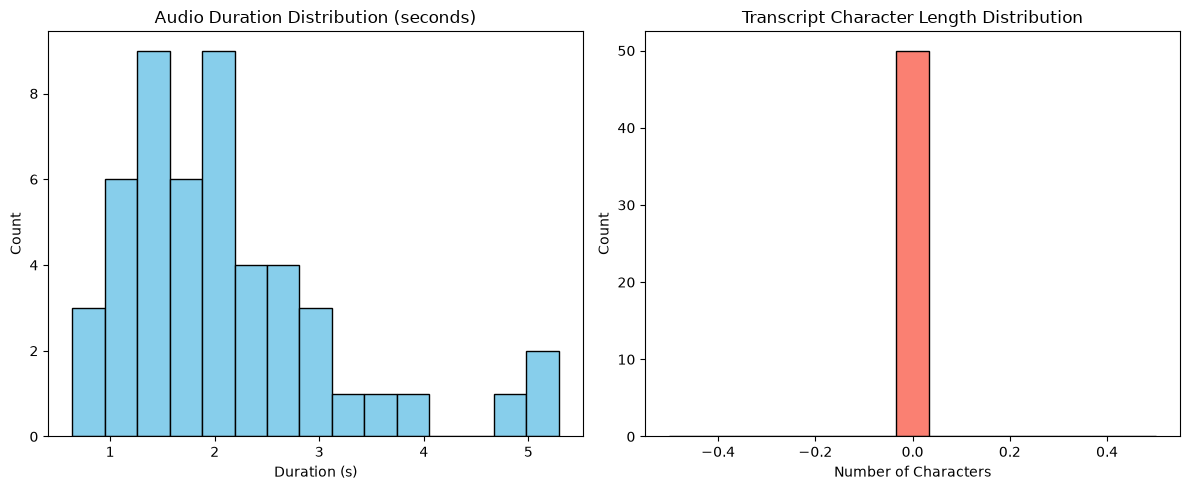

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df_stats["duration_sec"], bins=15, color="skyblue", edgecolor="black")
axes[0].set_title("Audio Duration Distribution (seconds)")
axes[0].set_xlabel("Duration (s)")
axes[0].set_ylabel("Count")

axes[1].hist(df_stats["text_length"], bins=15, color="salmon", edgecolor="black")
axes[1].set_title("Transcript Character Length Distribution")
axes[1].set_xlabel("Number of Characters")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

Let's print some sample transcriptions to check for spaces, punctuation, special symbols, or filler words in Thai.

In [7]:
print("Sample transcriptions:")
for idx, text in enumerate(texts[:5]):
    print(f"{idx + 1}. {text}")

Sample transcriptions:
1. 
2. 
3. 
4. 
5. 


## What We Learned
- **Streaming Mode**: Crucial for dealing with 114 hours of audio on consumer hardware without downloading massive files.
- **Data structure**: Each sample contains audio (sampling rate and numpy array) and transcript text.
- **Audio Rate**: Standardized sampling rate (usually 16kHz for speech recognition pipelines).

## Common Problems
- **Slow streaming**: Depending on network connection, streaming can pause. Caching a small validation set can help.
- **Thai Spacing**: Thai is written without word boundaries. Evaluation spacing normalization will be important for CER and WER calculation.

## Next Step
Proceed to **Phase 2: Text Normalization** to prepare a clean normalization utility for comparing predictions with ground truth.

## Suggested Commit
```bash
git add notebooks/01_lotusdis_exploration.ipynb
git commit -m "data: explore LOTUSDIS dataset"
```